# Mind the Prior Hole: Variational Autoencoders on CelebA

**A σ-VAE trained on 162k real face images (CelebA, 64×64), and a study of why sampling from the prior fails — and how a learned *ex-post* prior fixes it.**

---

### The story in one paragraph

A VAE learns an encoder $q_\phi(z\mid x)$ and a decoder $p_\theta(x\mid z)$ by maximising the ELBO, with a fixed prior $p(z)=\mathcal N(0, I)$.
Averaged over the data, the KL term of the ELBO splits into two pieces (Hoffman & Johnson, 2016, *ELBO surgery*):

$$
\mathbb E_{p(x)}\big[\mathrm{KL}(q_\phi(z\mid x)\,\|\,p(z))\big] \;=\; \underbrace{I_q(x;z)}_{\text{information in the code}} \;+\; \underbrace{\mathrm{KL}\big(q_\phi(z)\,\|\,p(z)\big)}_{\text{prior mismatch}}
$$

where $q_\phi(z)=\mathbb E_{p(x)}[q_\phi(z\mid x)]$ is the **aggregate posterior**. A decoder that reconstructs well needs a large $I_q(x;z)$, and the optimiser cannot drive the mismatch term to zero at the same time. As a result $q_\phi(z)$ does not fill the Gaussian ball. It leaves **holes**: regions with high prior density that the decoder never saw during training. Samples drawn from $\mathcal N(0,I)$ land in those holes and decode to distorted faces.

This notebook:
1. trains a convolutional **σ-VAE** (Gaussian decoder with an analytically optimal variance, Rybkin et al., 2021) on the full CelebA training split;
2. **measures the prior hole**: active units, the spectrum of the aggregate posterior, and the density that $q_\phi(z)$ assigns to prior samples;
3. replaces $\mathcal N(0,I)$ with priors fitted to the aggregate posterior after training (**ex-post density estimation**, Ghosh et al., 2020; the idea behind two-stage VAEs, Dai & Wipf, 2019): a full-covariance Gaussian and a Gaussian mixture;
4. compares the three priors with **FID** on 10k samples each;
5. uses the structure of the latent space for attribute editing (smile, glasses, …) with CelebA's 40 labelled attributes.

**Hardware:** one Colab T4 GPU. The training cell has a fixed time budget, so the whole notebook runs in about 1 h 15 min.

## 1. Setup

In [ ]:
!pip -q install torchmetrics torch-fidelity

import os, math, time, json, glob
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision.utils import make_grid, save_image

assert torch.cuda.is_available(), "Switch the runtime to GPU: Runtime > Change runtime type > T4 GPU"
device = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0), "| torch", torch.__version__)

SEED = 0
torch.manual_seed(SEED); np.random.seed(SEED)
torch.backends.cudnn.benchmark = True

CFG = dict(
    img_size=64,
    z_dim=128,
    channels=(64, 128, 256, 512),
    batch_size=256,
    lr=1e-3,
    min_lr=1e-5,
    warmup_steps=500,
    kl_warmup_steps=2000,       # linear KL annealing 0 -> 1
    train_time_budget_min=55,   # wall-clock budget for the training loop
    max_epochs=40,
)
OUT = "/content/outputs"
os.makedirs(f"{OUT}/figures", exist_ok=True)
os.makedirs(f"{OUT}/progress", exist_ok=True)

def show_grid(x, nrow=8, title=None, fname=None, figsize=(8, 8)):
    grid = make_grid(x.detach().float().clamp(0, 1).cpu(), nrow=nrow, padding=2, pad_value=1.0)
    plt.figure(figsize=figsize); plt.imshow(grid.permute(1, 2, 0).numpy()); plt.axis("off")
    if title: plt.title(title)
    if fname: plt.savefig(f"{OUT}/figures/{fname}", bbox_inches="tight", dpi=120)
    plt.show()

GPU: Tesla T4 | torch 2.14.1+cu130


## 2. Data: CelebA (aligned & cropped), 202,599 real celebrity faces

We use the official CelebA splits, mirrored on the Hugging Face Hub as Parquet (`flwrlabs/celeba`, images plus identity and 40 binary attributes). Identities do not overlap between splits.

Preprocessing follows the usual 64×64 CelebA protocol: a central 148×148 crop of the 178×218 aligned image, then a resize to 64×64. All images are decoded **once** into a `uint8` array (≈2.5 GB) that is cached on disk and then **kept on the GPU**. The training loop then has no data-loader bottleneck, which matters on Colab's 2 CPU cores.

In [ ]:
from concurrent.futures import ThreadPoolExecutor
from multiprocessing import get_context
from huggingface_hub import hf_hub_download
import pyarrow.parquet as pq
from PIL import Image
import io

REPO = "flwrlabs/celeba"
SHARDS = {"train": 19, "valid": 3, "test": 3}
CROP = (15, 40, 163, 188)          # 148x148 centre crop of the 178x218 aligned faces
CACHE = "/content/celeba64.npz"

def decode_image(b):
    im = Image.open(io.BytesIO(b)).convert("RGB").crop(CROP)
    return np.asarray(im.resize((CFG["img_size"],) * 2, Image.LANCZOS), dtype=np.uint8)

def load_split(split, pool):
    files = [f"img_align+identity+attr/{split}-{i:05d}-of-{SHARDS[split]:05d}.parquet" for i in range(SHARDS[split])]
    imgs, attrs, names = [], [], None
    with ThreadPoolExecutor(4) as ex:          # download ahead while decoding
        futs = [ex.submit(hf_hub_download, REPO, f, repo_type="dataset", local_dir="/content/hf") for f in files]
        for k, fut in enumerate(futs):
            path = fut.result()
            tab = pq.read_table(path)
            names = [c for c in tab.column_names if c not in ("image", "celeb_id")]
            raw = tab.column("image").combine_chunks().field("bytes").to_pylist()
            imgs.append(np.stack(pool.map(decode_image, raw, chunksize=256)))
            a = np.stack([np.asarray(tab.column(c).to_pylist()) for c in names], 1)
            attrs.append(a if a.dtype == bool else a > 0)   # handles bool or {-1, 1} encodings
            del tab, raw; os.remove(path)
            print(f"\r{split}: shard {k+1}/{len(files)}  images so far: {sum(map(len, imgs)):,}", end="")
    print()
    return np.concatenate(imgs), np.concatenate(attrs), names

if os.path.exists(CACHE):
    d = np.load(CACHE, allow_pickle=True)
    data = {k: d[k] for k in d.files}
    ATTR_NAMES = list(d["attr_names"])
else:
    t0 = time.time(); data = {}
    with get_context("fork").Pool(os.cpu_count()) as pool:
        for split in SHARDS:
            data[f"{split}_x"], data[f"{split}_a"], ATTR_NAMES = load_split(split, pool)
    np.savez(CACHE, **data, attr_names=np.array(ATTR_NAMES))
    print(f"done in {(time.time()-t0)/60:.1f} min")

for s in SHARDS:
    print(f"{s:>5}: {data[s+'_x'].shape}  {data[s+'_x'].dtype}")

# Images live on the GPU as uint8, NCHW: 162,770 x 3 x 64 x 64 = 2.0 GB
gpu = {s: torch.from_numpy(data[s + "_x"]).permute(0, 3, 1, 2).contiguous().to(device) for s in SHARDS}
attrs = {s: torch.from_numpy(data[s + "_a"]) for s in SHARDS}
N_TRAIN = len(gpu["train"])
print(f"GPU memory used by data: {torch.cuda.memory_allocated()/1e9:.2f} GB")

img_align+identity+attr/train-00003-of-0(…): reconstructing file:   0%|          |  0.00B /  490MB            

img_align+identity+attr/train-00002-of-0(…): reconstructing file:   0%|          |  0.00B /  494MB            

img_align+identity+attr/train-00001-of-0(…): reconstructing file:   0%|          |  0.00B /  498MB            

img_align+identity+attr/train-00000-of-0(…): reconstructing file:   0%|          |  0.00B /  500MB            

img_align+identity+attr/train-00002-of-0(…): downloading bytes:           |  0.00B            

img_align+identity+attr/train-00001-of-0(…): downloading bytes:           |  0.00B            

... (44 outputs left out)

img_align+identity+attr/test-00002-of-00(…): reconstructing file:   0%|          |  0.00B /  383MB            

img_align+identity+attr/test-00000-of-00(…): downloading bytes:           |  0.00B            

img_align+identity+attr/test-00002-of-00(…): downloading bytes:           |  0.00B            

test: shard 3/3  images so far: 19,962
done in 10.6 min
train: (162770, 64, 64, 3)  uint8
valid: (19867, 64, 64, 3)  uint8
 test: (19962, 64, 64, 3)  uint8
GPU memory used by data: 2.49 GB


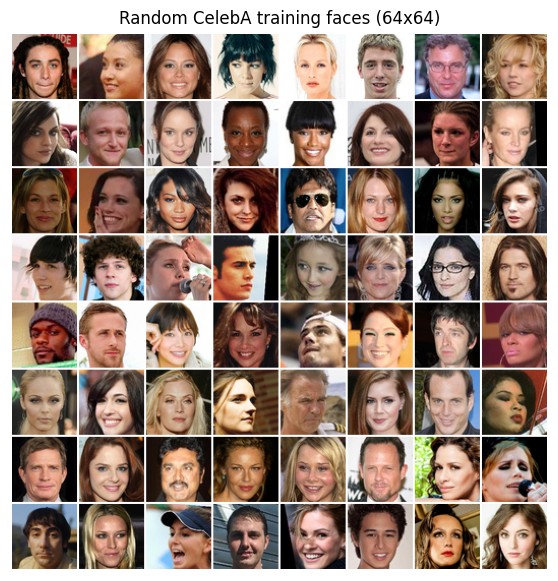

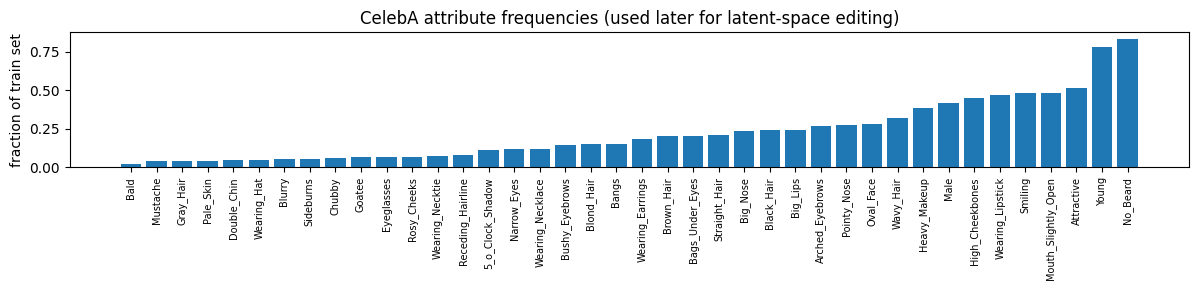

In [ ]:
show_grid(gpu["train"][torch.randperm(N_TRAIN, device=device)[:64]].float() / 255,
          title="Random CelebA training faces (64x64)", fname="data_samples.png", figsize=(7, 7))

freq = attrs["train"].float().mean(0).numpy()
order = np.argsort(freq)
plt.figure(figsize=(12, 3))
plt.bar(range(len(freq)), freq[order]); plt.xticks(range(len(freq)), [ATTR_NAMES[i] for i in order], rotation=90, fontsize=7)
plt.ylabel("fraction of train set"); plt.title("CelebA attribute frequencies (used later for latent-space editing)")
plt.tight_layout(); plt.show()

## 3. Model: a convolutional σ-VAE

**Encoder:** 64 → 32 → 16 → 8 → 4, each stage a strided convolution followed by a residual block, then a linear layer that outputs $\mu_\phi(x)$ and $\log\sigma^2_\phi(x)$ for a 128-dimensional diagonal Gaussian.
**Decoder:** the mirror image, using nearest-neighbour upsampling + 3×3 convolutions (this avoids checkerboard artifacts).

**Likelihood.** The most common reason VAE samples look blurry is an arbitrary choice of decoder variance. A plain MSE loss silently fixes $\sigma^2 = 1/2$, which is a large β on data in $[0,1]$. Following **σ-VAE** (Rybkin, Daniilidis & Levine, 2021), we use a Gaussian decoder $p_\theta(x\mid z)=\mathcal N(\hat x_\theta(z), \sigma^2 I)$ with one shared variance that is set to its analytic maximum-likelihood value at every step, $\sigma^{2\,*} = \mathrm{MSE}(x,\hat x)$. The balance between reconstruction and KL is then *learned* rather than hand-tuned, so there is no β to tune:

$$
\mathcal L(x) = \underbrace{\tfrac{1}{2\sigma^{2*}}\|x-\hat x\|^2 + \tfrac{D}{2}\log(2\pi\sigma^{2*})}_{-\log p_\theta(x\mid z)} \;+\; \mathrm{KL}\big(q_\phi(z\mid x)\,\|\,\mathcal N(0,I)\big)
$$

A side effect worth knowing for the rest of the notebook: as reconstructions improve, $\sigma^*$ shrinks and the KL becomes relatively cheap. The model therefore puts a lot of information into $z$, which is exactly the regime where the prior hole appears.

In [ ]:
class ResBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.f = nn.Sequential(
            nn.BatchNorm2d(ch), nn.SiLU(), nn.Conv2d(ch, ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(ch), nn.SiLU(), nn.Conv2d(ch, ch, 3, padding=1))
    def forward(self, x):
        return x + self.f(x)

class Encoder(nn.Module):
    def __init__(self, z_dim, chs):
        super().__init__()
        layers, c_in = [nn.Conv2d(3, chs[0], 3, padding=1)], chs[0]
        for c in chs:                                          # 64 -> 32 -> 16 -> 8 -> 4
            layers += [nn.Conv2d(c_in, c, 4, stride=2, padding=1), ResBlock(c)]
            c_in = c
        layers += [nn.BatchNorm2d(c_in), nn.SiLU(), nn.Flatten()]
        self.net = nn.Sequential(*layers)
        self.head = nn.Linear(c_in * 16, 2 * z_dim)
    def forward(self, x):
        mu, logvar = self.head(self.net(x)).float().chunk(2, dim=1)
        return mu, logvar.clamp(-14.0, 6.0)

class Decoder(nn.Module):
    def __init__(self, z_dim, chs):
        super().__init__()
        rc = list(chs[::-1])                                   # 512, 256, 128, 64
        self.c0 = rc[0]
        self.fc = nn.Linear(z_dim, rc[0] * 16)
        layers, c_in = [], rc[0]
        for c in rc[1:] + [rc[-1]]:                            # 4 -> 8 -> 16 -> 32 -> 64
            layers += [ResBlock(c_in), nn.Upsample(scale_factor=2, mode="nearest"),
                       nn.Conv2d(c_in, c, 3, padding=1)]
            c_in = c
        layers += [nn.BatchNorm2d(c_in), nn.SiLU(), nn.Conv2d(c_in, 3, 3, padding=1)]
        self.net = nn.Sequential(*layers)
    def forward(self, z):
        return torch.sigmoid(self.net(self.fc(z).view(-1, self.c0, 4, 4)).float())

class VAE(nn.Module):
    def __init__(self, z_dim=128, chs=(64, 128, 256, 512)):
        super().__init__()
        self.z_dim = z_dim
        self.enc, self.dec = Encoder(z_dim, chs), Decoder(z_dim, chs)
    def forward(self, x):
        mu, logvar = self.enc(x)
        z = mu + torch.randn_like(mu) * (0.5 * logvar).exp()   # reparameterisation trick
        return self.dec(z), mu, logvar

def vae_terms(x, x_hat, mu, logvar):
    # Per-image negative log-likelihood (nats) under the sigma-VAE decoder, and KL to N(0, I).
    D = x[0].numel()
    sq = (x_hat - x).pow(2).flatten(1).sum(1)
    log_sigma = 0.5 * torch.log(sq.mean().detach() / D).clamp_min(-6.0)   # analytic optimum, soft floor
    nll = 0.5 * sq * torch.exp(-2 * log_sigma) + D * log_sigma + 0.5 * D * math.log(2 * math.pi)
    kl = 0.5 * (mu.pow(2) + logvar.exp() - 1.0 - logvar).sum(1)
    return nll, kl, log_sigma

def to_float(xb_uint8, flip=False):
    x = xb_uint8.float().div_(255)
    if flip:                                                   # random horizontal flip augmentation
        m = torch.rand(x.shape[0], device=x.device) < 0.5
        x[m] = x[m].flip(-1)
    return x.contiguous(memory_format=torch.channels_last)

model = VAE(CFG["z_dim"], CFG["channels"]).to(device).to(memory_format=torch.channels_last)
print(f"parameters: {sum(p.numel() for p in model.parameters())/1e6:.1f} M")

# Sanity check: shapes, finite loss, and that the KL is ~0 at initialisation-scale outputs
with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
    xb = to_float(gpu["train"][:16])
    x_hat, mu, logvar = model(xb)
    nll, kl, ls = vae_terms(xb, x_hat, mu, logvar)
print("x_hat", tuple(x_hat.shape), "| mu", tuple(mu.shape), "| nll/img %.1f  kl/img %.1f  sigma %.3f" % (nll.mean(), kl.mean(), ls.exp()))
assert x_hat.shape == xb.shape and torch.isfinite(nll).all() and torch.isfinite(kl).all()

parameters: 20.1 M
x_hat (16, 3, 64, 64) | mu (16, 128) | nll/img 1442.6  kl/img 12.5  sigma 0.272


## 4. Throughput check → number of epochs

We time 30 real training steps (on a throwaway copy of the model) and pick the number of epochs that fits the time budget. The training loop also stops early if the budget runs out, so the run never overshoots.

In [ ]:
import copy
bench = copy.deepcopy(model).train()
opt_b = torch.optim.Adam(bench.parameters(), lr=1e-4)
scaler_b = torch.amp.GradScaler()
B = CFG["batch_size"]

def bench_step():
    idx = torch.randint(0, N_TRAIN, (B,), device=device)
    x = to_float(gpu["train"][idx], flip=True)
    with torch.autocast("cuda", dtype=torch.float16):
        x_hat, mu, logvar = bench(x)
    nll, kl, _ = vae_terms(x, x_hat, mu, logvar)
    loss = (nll + kl).mean() / x[0].numel()
    opt_b.zero_grad(set_to_none=True); scaler_b.scale(loss).backward(); scaler_b.step(opt_b); scaler_b.update()

for _ in range(10): bench_step()                 # warm-up (cudnn autotune)
torch.cuda.synchronize(); t0 = time.time()
for _ in range(30): bench_step()
torch.cuda.synchronize(); step_t = (time.time() - t0) / 30
del bench, opt_b, scaler_b; torch.cuda.empty_cache()

steps_per_epoch = N_TRAIN // B
epoch_min = step_t * steps_per_epoch / 60 * 1.04  # +4% for the validation pass
EPOCHS = int(max(3, min(CFG["max_epochs"], CFG["train_time_budget_min"] // epoch_min)))
print(f"{step_t*1000:.0f} ms/step | {steps_per_epoch} steps/epoch | ~{epoch_min:.2f} min/epoch")
print(f"-> training for {EPOCHS} epochs (~{EPOCHS*epoch_min:.0f} min, {EPOCHS*steps_per_epoch:,} steps)")

153 ms/step | 635 steps/epoch | ~1.68 min/epoch
-> training for 32 epochs (~54 min, 20,320 steps)


## 5. Training

Note: the NLL of a continuous Gaussian decoder is a *density*, so with a small σ* it is negative (a large density value). This is normal; lower is still better.

Adam with linear warm-up and cosine decay, mixed precision (fp16 autocast; the loss is computed in fp32), KL annealing over the first 2,000 steps, and random horizontal flips.
After every epoch the loop evaluates on the **validation** split, saves a checkpoint, and decodes a fixed batch of prior samples into `outputs/progress/` so you can watch the model improve.

In [ ]:
model = VAE(CFG["z_dim"], CFG["channels"]).to(device).to(memory_format=torch.channels_last)
opt = torch.optim.Adam(model.parameters(), lr=CFG["lr"])
total_steps = EPOCHS * steps_per_epoch
def lr_lambda(s):
    if s < CFG["warmup_steps"]:
        return (s + 1) / CFG["warmup_steps"]
    p = (s - CFG["warmup_steps"]) / max(1, total_steps - CFG["warmup_steps"])
    return CFG["min_lr"] / CFG["lr"] + (1 - CFG["min_lr"] / CFG["lr"]) * 0.5 * (1 + math.cos(math.pi * min(p, 1.0)))
sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
scaler = torch.amp.GradScaler()
D = 3 * CFG["img_size"] ** 2
z_fixed = torch.randn(64, CFG["z_dim"], device=device, generator=torch.Generator(device=device).manual_seed(1))

@torch.no_grad()
def evaluate(split="valid", n=10_000, bs=500):
    model.eval(); tot = np.zeros(3)
    xs = gpu[split][:n]
    for i in range(0, len(xs), bs):
        x = to_float(xs[i:i + bs])
        with torch.autocast("cuda", dtype=torch.float16):
            mu, logvar = model.enc(x)
            x_hat = model.dec(mu + torch.randn_like(mu) * (0.5 * logvar).exp())
        nll, kl, _ = vae_terms(x, x_hat, mu, logvar)
        mse = (x_hat - x).pow(2).flatten(1).mean(1)
        tot += np.array([nll.sum().item(), kl.sum().item(), mse.sum().item()])
    model.train()
    nll, kl, mse = (tot / len(xs)).tolist()
    return dict(nll=nll, kl=kl, neg_elbo=nll + kl, mse=mse, psnr=10 * math.log10(1 / mse))

history, step, t_start = [], 0, time.time()
budget_s = CFG["train_time_budget_min"] * 60
model.train()
for epoch in range(1, EPOCHS + 1):
    perm = torch.randperm(N_TRAIN, device=device)
    logs = []; t_ep = time.time()
    for i in range(steps_per_epoch):
        x = to_float(gpu["train"][perm[i * B:(i + 1) * B]], flip=True)
        beta = min(1.0, step / CFG["kl_warmup_steps"])
        with torch.autocast("cuda", dtype=torch.float16):
            x_hat, mu, logvar = model(x)
        nll, kl, log_sigma = vae_terms(x, x_hat, mu, logvar)
        loss = (nll + beta * kl).mean() / D                   # per-dimension scale keeps Adam well-conditioned
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update(); sched.step(); step += 1
        if i % 50 == 0:
            logs.append((nll.mean().item(), kl.mean().item(), log_sigma.exp().item()))
    tr = np.mean(logs, 0).tolist()
    val = evaluate("valid")
    history.append(dict(epoch=epoch, step=step, train_nll=tr[0], train_kl=tr[1], sigma=tr[2],
                        lr=sched.get_last_lr()[0], minutes=(time.time() - t_start) / 60, **{f"val_{k}": v for k, v in val.items()}))
    print(f"ep {epoch:2d}/{EPOCHS} | train nll {tr[0]:8.1f} kl {tr[1]:6.1f} sigma {tr[2]:.4f} | "
          f"val -ELBO {val['neg_elbo']:8.1f} kl {val['kl']:6.1f} psnr {val['psnr']:5.2f} dB | "
          f"{(time.time()-t_ep)/60:.1f} min/ep, total {(time.time()-t_start)/60:.1f} min")
    model.eval()
    with torch.no_grad():
        save_image(model.dec(z_fixed), f"{OUT}/progress/epoch_{epoch:02d}.png", nrow=8)
    model.train()
    torch.save({"model": model.state_dict(), "cfg": CFG, "history": history}, f"{OUT}/vae_celeba64.pt")
    json.dump(history, open(f"{OUT}/history.json", "w"), indent=1)
    if time.time() - t_start > budget_s:
        print("time budget reached, stopping early"); break

model.eval()
print(f"finished: {step:,} steps in {(time.time()-t_start)/60:.1f} min")

ep  1/32 | train nll  -9446.6 kl  527.5 sigma 0.1213 | val -ELBO -12592.6 kl  698.6 psnr 21.72 dB | 1.9 min/ep, total 1.9 min
ep  2/32 | train nll -13939.6 kl  632.9 sigma 0.0779 | val -ELBO -13762.5 kl  558.5 psnr 22.44 dB | 1.9 min/ep, total 3.8 min
ep  3/32 | train nll -14634.4 kl  503.5 sigma 0.0736 | val -ELBO -14178.9 kl  465.6 psnr 22.67 dB | 1.9 min/ep, total 5.7 min
ep  4/32 | train nll -14935.2 kl  447.1 sigma 0.0718 | val -ELBO -14560.1 kl  446.1 psnr 22.93 dB | 1.9 min/ep, total 7.5 min
ep  5/32 | train nll -15032.5 kl  436.2 sigma 0.0712 | val -ELBO -14520.5 kl  435.6 psnr 22.89 dB | 1.9 min/ep, total 9.4 min
ep  6/32 | train nll -15282.5 kl  430.3 sigma 0.0698 | val -ELBO -14949.7 kl  420.9 psnr 23.19 dB | 1.9 min/ep, total 11.3 min
ep  7/32 | train nll -15369.3 kl  425.9 sigma 0.0693 | val -ELBO -15015.7 kl  422.9 psnr 23.23 dB | 1.9 min/ep, total 13.2 min
ep  8/32 | train nll -15510.9 kl  425.6 sigma 0.0685 | val -ELBO -15111.3 kl  421.5 psnr 23.30 dB | 1.9 min/ep, tota

## 6. Training curves

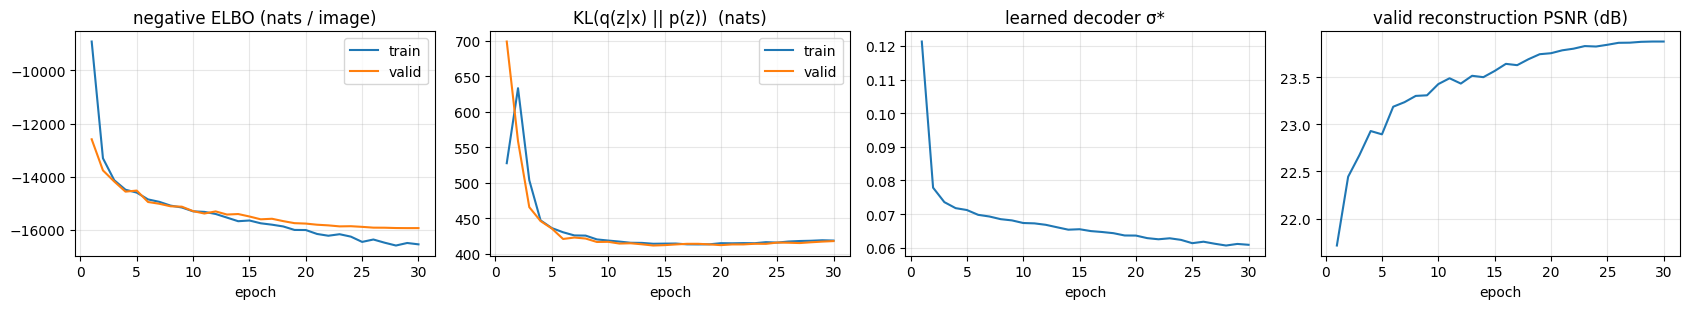

In [ ]:
# Reload from the checkpoint, so the analysis also works after a runtime restart
ckpt = torch.load(f"{OUT}/vae_celeba64.pt", map_location=device)
model = VAE(CFG["z_dim"], CFG["channels"]).to(device).to(memory_format=torch.channels_last)
model.load_state_dict(ckpt["model"]); model.eval()
history = ckpt["history"]

ep = [h["epoch"] for h in history]
fig, ax = plt.subplots(1, 4, figsize=(17, 3.2))
ax[0].plot(ep, [h["train_nll"] + h["train_kl"] for h in history], label="train"); ax[0].plot(ep, [h["val_neg_elbo"] for h in history], label="valid")
ax[0].set_title("negative ELBO (nats / image)"); ax[0].legend()
ax[1].plot(ep, [h["train_kl"] for h in history], label="train"); ax[1].plot(ep, [h["val_kl"] for h in history], label="valid")
ax[1].set_title("KL(q(z|x) || p(z))  (nats)"); ax[1].legend()
ax[2].plot(ep, [h["sigma"] for h in history]); ax[2].set_title("learned decoder σ*")
ax[3].plot(ep, [h["val_psnr"] for h in history]); ax[3].set_title("valid reconstruction PSNR (dB)")
for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/figures/training_curves.png", dpi=120); plt.show()

## 7. Reconstructions on the held-out test set

The test identities were never seen during training. Each pair of rows shows the originals on top and the reconstructions $\hat x(\mu_\phi(x))$ below.

test set (19,962 images): -ELBO -16018.1 nats | KL 418.8 nats | MSE 0.00404 | PSNR 23.94 dB


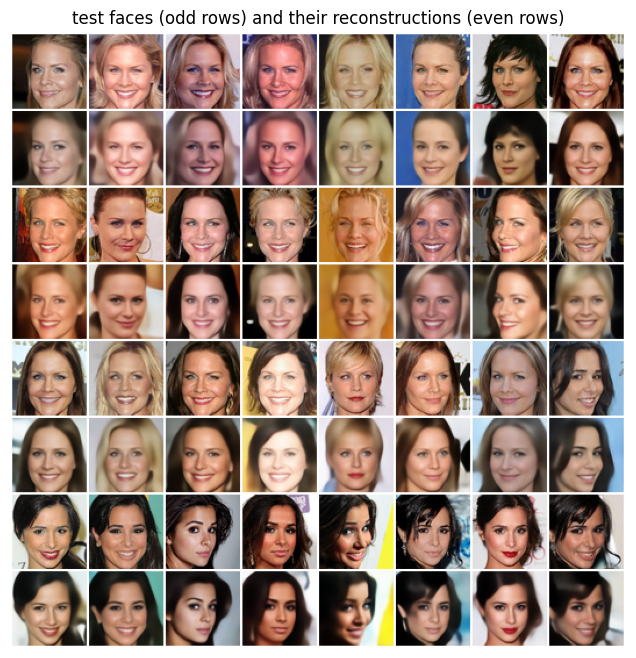

In [ ]:
@torch.no_grad()
def encode(split, bs=1000):
    mus, lvs = [], []
    for i in range(0, len(gpu[split]), bs):
        with torch.autocast("cuda", dtype=torch.float16):
            mu, lv = model.enc(to_float(gpu[split][i:i + bs]))
        mus.append(mu.float()); lvs.append(lv.float())
    return torch.cat(mus), torch.cat(lvs)

@torch.no_grad()
def decode(z, bs=1000):
    out = []
    for i in range(0, len(z), bs):
        with torch.autocast("cuda", dtype=torch.float16):
            out.append(model.dec(z[i:i + bs]).float())
    return torch.cat(out)

test_res = evaluate("test", n=len(gpu["test"]))
print("test set ({:,} images): -ELBO {neg_elbo:.1f} nats | KL {kl:.1f} nats | MSE {mse:.5f} | PSNR {psnr:.2f} dB".format(len(gpu["test"]), **test_res))

mu_tr, lv_tr = encode("train")
mu_te, lv_te = encode("test")
x = to_float(gpu["test"][:32])
rec = decode(mu_te[:32])
rows = torch.cat([torch.cat([x[i:i + 8], rec[i:i + 8]]) for i in range(0, 32, 8)])
show_grid(rows, nrow=8, title="test faces (odd rows) and their reconstructions (even rows)", fname="reconstructions.png")

## 8. Diagnosing the prior hole

Three views of how far the aggregate posterior $q_\phi(z)$ is from $p(z)=\mathcal N(0,I)$:

* **KL per latent dimension and active units** (Burda et al., 2016). A dimension is *active* if $\mathrm{Var}_x\big[\mu_\phi(x)_d\big] > 0.01$, meaning the encoder actually uses it.
* **Spectrum of the aggregate posterior.** If $q_\phi(z)$ matched the prior, every eigenvalue of $\mathrm{Cov}_{q}[z]$ would be 1. We also report the KL between the moment-matched Gaussian $\mathcal N(m,\Sigma)$ and $\mathcal N(0,I)$, a cheap closed-form proxy for the mismatch term.
* **Norms.** In 128 dimensions, prior samples concentrate on a thin shell of radius $\approx\sqrt{128}\approx 11.3$. Encoded faces do not have to.

active units: 128 / 128
average KL per image: 418.8 nats  (upper bound on I(x;z) + KL(q(z)||p(z)))
moment-matched KL(N(m,S) || N(0,I)): 15.4 nats  |  eigenvalues of Cov_q[z]: max 7.07, min 0.316


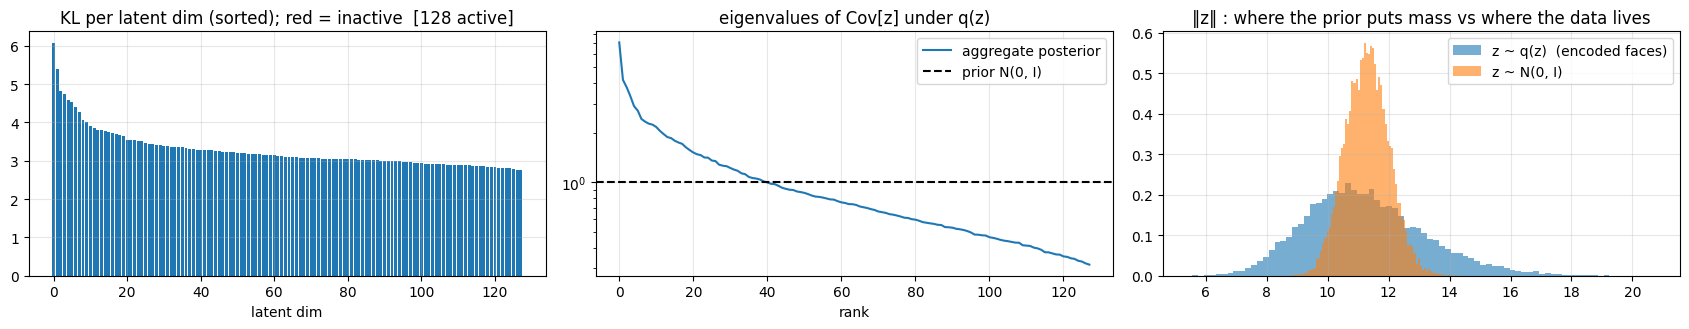

In [ ]:
z_tr = mu_tr + torch.randn_like(mu_tr) * (0.5 * lv_tr).exp()        # one sample per image from q(z|x)
kl_dim = (0.5 * (mu_te.pow(2) + lv_te.exp() - 1 - lv_te)).mean(0).cpu().numpy()
au_var = mu_tr.var(0).cpu().numpy()
active = au_var > 0.01

m = z_tr.mean(0); C = torch.cov(z_tr.T.double())
eig = torch.linalg.eigvalsh(C).flip(0).cpu().numpy()
kl_mm = 0.5 * (torch.trace(C) + m.double() @ m.double() - CFG["z_dim"] - torch.logdet(C)).item()

print(f"active units: {active.sum()} / {CFG['z_dim']}")
print(f"average KL per image: {kl_dim.sum():.1f} nats  (upper bound on I(x;z) + KL(q(z)||p(z)))")
print(f"moment-matched KL(N(m,S) || N(0,I)): {kl_mm:.1f} nats  |  eigenvalues of Cov_q[z]: max {eig[0]:.2f}, min {eig[-1]:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(17, 3.4))
o = np.argsort(-kl_dim)
ax[0].bar(range(len(kl_dim)), kl_dim[o], color=np.where(active[o], "C0", "C3"))
ax[0].set_title(f"KL per latent dim (sorted); red = inactive  [{active.sum()} active]"); ax[0].set_xlabel("latent dim")
ax[1].semilogy(eig, label="aggregate posterior"); ax[1].axhline(1.0, color="k", ls="--", label="prior N(0, I)")
ax[1].set_title("eigenvalues of Cov[z] under q(z)"); ax[1].legend(); ax[1].set_xlabel("rank")
z_prior = torch.randn_like(z_tr[:20000])
ax[2].hist(z_tr[:20000].norm(dim=1).cpu(), bins=80, alpha=.6, density=True, label="z ~ q(z)  (encoded faces)")
ax[2].hist(z_prior.norm(dim=1).cpu(), bins=80, alpha=.6, density=True, label="z ~ N(0, I)")
ax[2].set_title("‖z‖ : where the prior puts mass vs where the data lives"); ax[2].legend()
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/figures/prior_hole_diagnostics.png", dpi=120); plt.show()

## 9. Learning a better prior after training (ex-post density estimation)

The decoder only knows how to decode regions where $q_\phi(z)$ has mass. So we sample from a density **fitted to $q_\phi(z)$**, not from $\mathcal N(0,I)$. The encoder and decoder stay frozen; only the prior changes:

| prior | parameters | what it captures |
|---|---|---|
| $\mathcal N(0, I)$ | 0 | the prior the VAE was trained with |
| full-covariance Gaussian $\mathcal N(m,\Sigma)$ | ~8k | the global shape (correlations, scale) of $q_\phi(z)$ |
| Gaussian mixture, $K=10$, full covariance | ~84k | multimodality: different "kinds" of faces |

We fit them on one posterior sample $z\sim q_\phi(z\mid x)$ per training image (the mixture uses a 100k random subset, ~10k points per component to keep EM fast on Colab's CPU). This is the recipe of Ghosh et al. (2020) and the reason two-stage VAEs (Dai & Wipf, 2019) and the learned priors of modern latent generative models (VQ-VAE + PixelCNN, latent diffusion) work: **the autoencoder learns a good representation; a separate model learns where in that representation the data lives.**

In [ ]:
from sklearn.mixture import GaussianMixture

class GaussPrior:
    def __init__(self, z):
        self.m = z.mean(0).double(); self.C = torch.cov(z.T.double())
        self.d = torch.distributions.MultivariateNormal(self.m, covariance_matrix=self.C)
    def sample(self, n): return self.d.sample((n,)).float()
    def log_prob(self, z): return self.d.log_prob(z.double()).float()

class StdNormal:
    def __init__(self, dim): self.d = torch.distributions.MultivariateNormal(torch.zeros(dim, device=device), torch.eye(dim, device=device))
    def sample(self, n): return self.d.sample((n,))
    def log_prob(self, z): return self.d.log_prob(z)

class GMMPrior:
    def __init__(self, z, k=10, n_fit=100_000, seed=0):
        idx = np.random.default_rng(seed).choice(len(z), n_fit, replace=False)
        t0 = time.time()
        self.g = GaussianMixture(k, covariance_type="full", max_iter=100, tol=1e-3, reg_covar=1e-5, random_state=seed)
        self.g.fit(z[idx].cpu().numpy())
        print(f"GMM(K={k}) fitted in {time.time()-t0:.0f}s, converged={self.g.converged_}, iters={self.g.n_iter_}")
    def sample(self, n):
        s, _ = self.g.sample(n); s = s[np.random.permutation(n)]   # sklearn returns samples grouped by component
        return torch.from_numpy(s).float().to(device)
    def log_prob(self, z): return torch.from_numpy(self.g.score_samples(z.cpu().numpy())).float().to(device)

priors = {"N(0, I)": StdNormal(CFG["z_dim"]), "Gaussian N(m, S)": GaussPrior(z_tr), "GMM (K=10)": GMMPrior(z_tr)}

# Held-out log-likelihood of encoded *test* faces under each prior (higher = closer to q(z))
z_te = mu_te + torch.randn_like(mu_te) * (0.5 * lv_te).exp()
for name, p in priors.items():
    print(f"{name:>18}: mean log p(z_test) = {p.log_prob(z_te).mean().item():9.1f} nats")

GMM(K=10) fitted in 268s, converged=True, iters=49
           N(0, I): mean log p(z_test) =    -182.1 nats
  Gaussian N(m, S): mean log p(z_test) =    -166.6 nats
        GMM (K=10): mean log p(z_test) =    -155.4 nats


### 9.1 Where do prior samples land?

We use the GMM as a density model of $q_\phi(z)$ and ask how much density it assigns to points drawn from each prior. Points from $\mathcal N(0,I)$ get far lower density than real encoded test faces. That is the hole, measured directly.

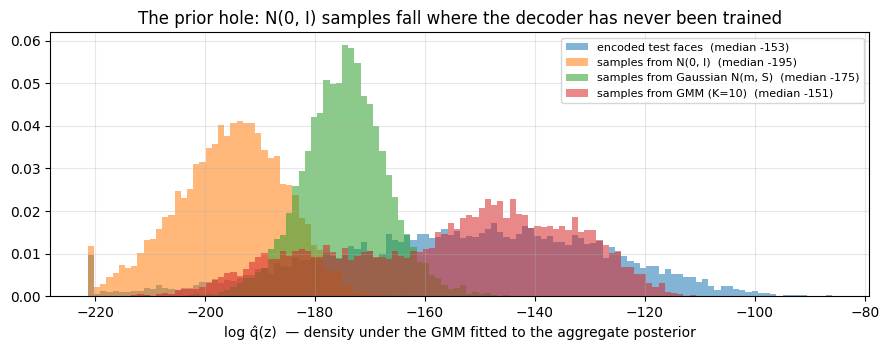

In [ ]:
gmm = priors["GMM (K=10)"]
n = 10_000
lp = {"encoded test faces": gmm.log_prob(z_te[:n]).cpu().numpy()}
for name in ["N(0, I)", "Gaussian N(m, S)", "GMM (K=10)"]:
    lp[f"samples from {name}"] = gmm.log_prob(priors[name].sample(n)).cpu().numpy()

lo = np.percentile(np.concatenate(list(lp.values())), 0.5); hi = max(v.max() for v in lp.values())
plt.figure(figsize=(9, 3.6))
for k, v in lp.items():
    plt.hist(np.clip(v, lo, hi), bins=120, range=(lo, hi), alpha=.55, density=True, label=f"{k}  (median {np.median(v):.0f})")
plt.xlabel("log q̂(z)  — density under the GMM fitted to the aggregate posterior"); plt.legend(fontsize=8)
plt.title("The prior hole: N(0, I) samples fall where the decoder has never been trained")
plt.grid(alpha=.3); plt.tight_layout(); plt.savefig(f"{OUT}/figures/prior_hole_density.png", dpi=120); plt.show()

### 9.2 Samples from each prior

Same decoder, same weights. Only the distribution we draw $z$ from changes.

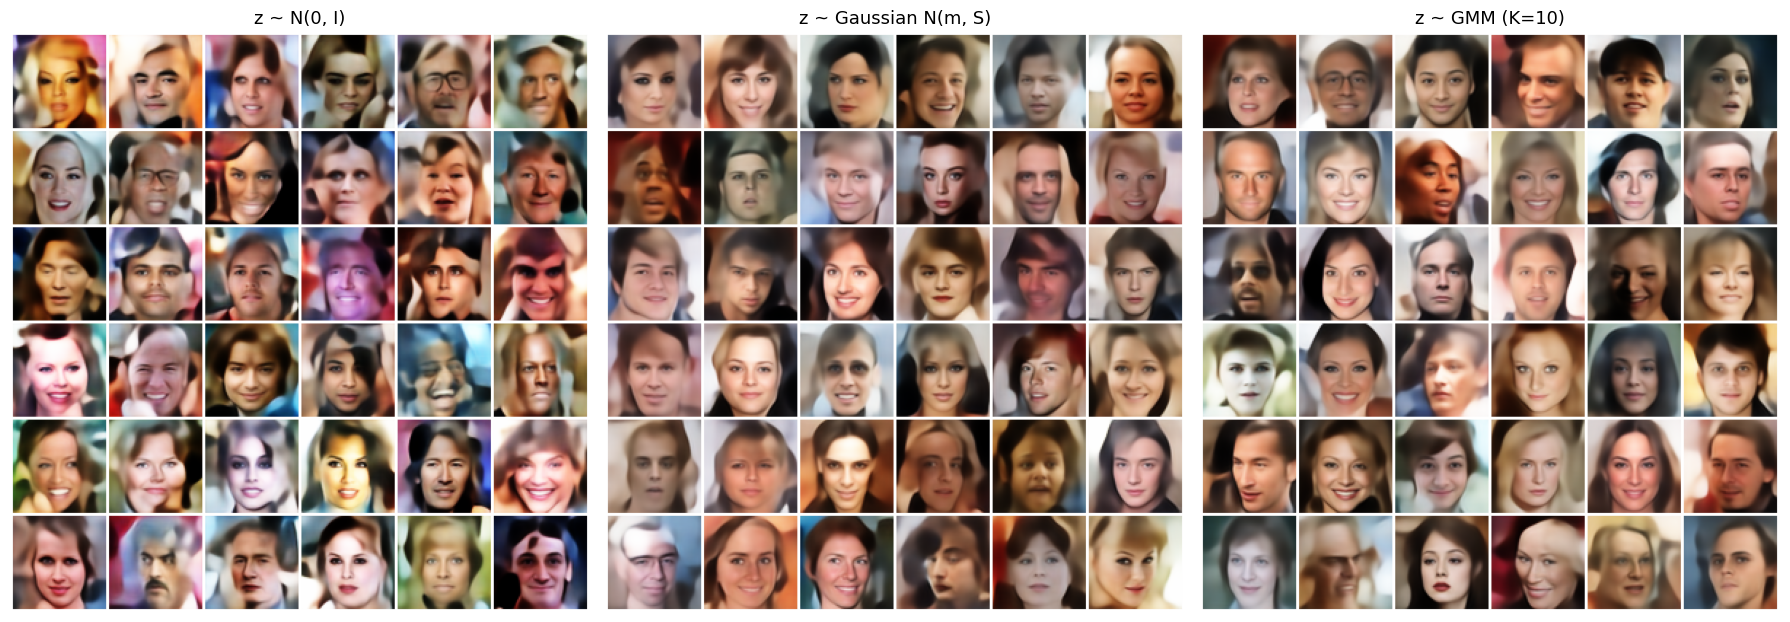

In [ ]:
torch.manual_seed(123)
samples = {name: decode(p.sample(10_000)) for name, p in priors.items()}
fig, ax = plt.subplots(1, 3, figsize=(18, 6.4))
for a, (name, s) in zip(ax, samples.items()):
    a.imshow(make_grid(s[:36].cpu(), nrow=6, padding=2, pad_value=1).permute(1, 2, 0)); a.set_title(f"z ~ {name}", fontsize=13); a.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/figures/samples_by_prior.png", dpi=120, bbox_inches="tight"); plt.show()

### 9.3 FID (10k samples vs 10k real test faces)

Fréchet Inception Distance (lower is better), computed with `torchmetrics` on Inception-v3 pool features. The FID of the **reconstructions** is a practical lower bound for any prior that uses this decoder: a perfect prior would sample codes that look exactly like encoded real faces.

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:01<00:00, 89.0MB/s]


FID   reconstructions (bound):  53.30
FID                   N(0, I):  92.15
FID          Gaussian N(m, S):  67.19
FID                GMM (K=10):  60.97


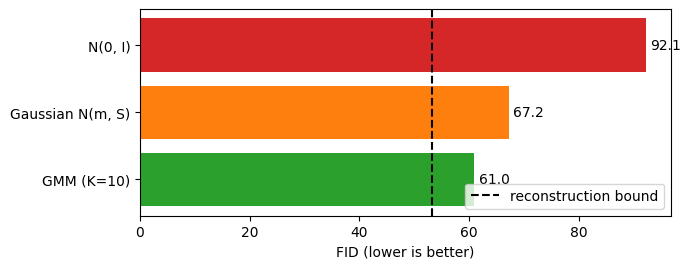

In [ ]:
from torchmetrics.image.fid import FrechetInceptionDistance
fid = FrechetInceptionDistance(feature=2048, normalize=True, reset_real_features=False).to(device)

def feed(imgs, real, bs=250):
    for i in range(0, len(imgs), bs):
        fid.update(imgs[i:i + bs].to(device), real=real)

real = to_float(gpu["test"][:10_000]).contiguous()
feed(real, real=True)
results = {}
for name, imgs in [("reconstructions (bound)", decode(mu_te[:10_000]))] + list(samples.items()):
    fid.reset(); feed(imgs, real=False)
    results[name] = fid.compute().item()
    print(f"FID  {name:>24}: {results[name]:6.2f}")

plt.figure(figsize=(7, 2.8))
names = list(results)[1:]
b = plt.barh(names, [results[k] for k in names], color=["C3", "C1", "C2"])
plt.axvline(results["reconstructions (bound)"], color="k", ls="--", label="reconstruction bound")
plt.bar_label(b, fmt="%.1f", padding=3); plt.xlabel("FID (lower is better)"); plt.legend(loc="lower right")
plt.gca().invert_yaxis(); plt.tight_layout(); plt.savefig(f"{OUT}/figures/fid.png", dpi=120); plt.show()

## 10. Using the latent space: attribute vectors and interpolation

CelebA's 40 binary attributes let us find semantic directions without any extra training. For each attribute, the direction is $v_a = \mathbb E[\mu_\phi(x)\mid a{=}1] - \mathbb E[\mu_\phi(x)\mid a{=}0]$, computed on the training set. We then edit unseen test faces with $\hat x\big(\mu_\phi(x) + \alpha\, v_a\big)$.

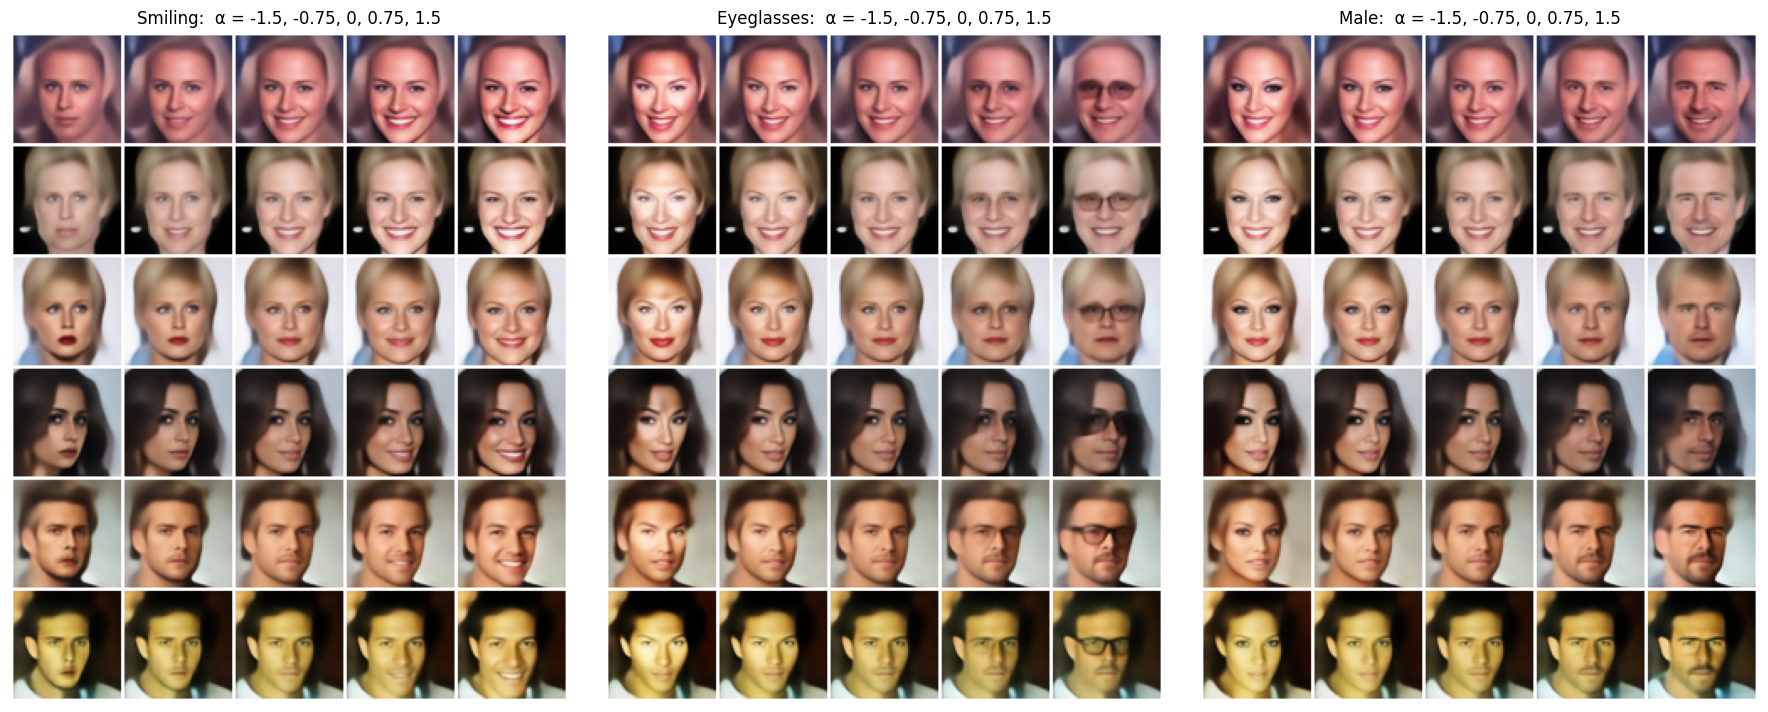

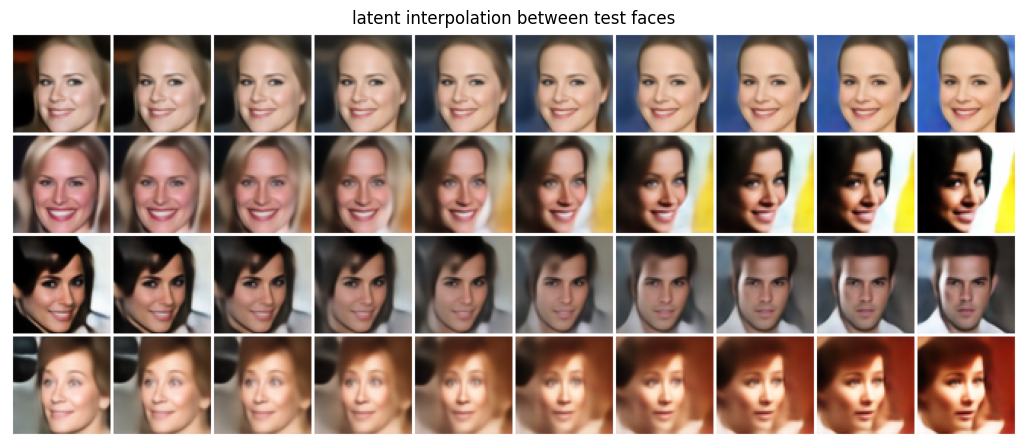

In [ ]:
A = attrs["train"]
def attr_vec(name):
    j = ATTR_NAMES.index(name)
    return mu_tr[A[:, j].to(device)].mean(0) - mu_tr[~A[:, j].to(device)].mean(0)

alphas = torch.tensor([-1.5, -0.75, 0.0, 0.75, 1.5], device=device)
faces = torch.tensor([3, 11, 20, 42, 57, 77], device=device)
fig, ax = plt.subplots(1, 3, figsize=(18, 7))
for a, name in zip(ax, ["Smiling", "Eyeglasses", "Male"]):
    v = attr_vec(name)
    z = (mu_te[faces][:, None, :] + alphas[None, :, None] * v).reshape(-1, CFG["z_dim"])
    a.imshow(make_grid(decode(z).cpu(), nrow=len(alphas), padding=2, pad_value=1).permute(1, 2, 0))
    a.set_title(f"{name}:  α = {', '.join(f'{x:g}' for x in alphas.tolist())}", fontsize=12); a.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/figures/attribute_editing.png", dpi=120, bbox_inches="tight"); plt.show()

# Linear interpolation between pairs of unseen test faces
pairs = [(0, 5), (13, 28), (31, 64), (90, 101)]
t = torch.linspace(0, 1, 10, device=device)[:, None]
z = torch.cat([(1 - t) * mu_te[i] + t * mu_te[j] for i, j in pairs])
show_grid(decode(z), nrow=10, title="latent interpolation between test faces", fname="interpolation.png", figsize=(13, 5.6))

## 11. Save results

In [ ]:
summary = dict(
    dataset="CelebA (aligned, 148px centre crop -> 64x64), official splits",
    n_train=int(N_TRAIN), epochs_trained=len(history), train_minutes=round(history[-1]["minutes"], 1),
    test=test_res, active_units=int(active.sum()), z_dim=CFG["z_dim"],
    moment_matched_kl=kl_mm, fid=results,
)
json.dump(summary, open(f"{OUT}/results.json", "w"), indent=2, default=float)
print(json.dumps(summary, indent=2, default=float))

# A GIF of the fixed-noise prior samples across training epochs
from PIL import Image as _Im
frames = [_Im.open(f) for f in sorted(glob.glob(f"{OUT}/progress/epoch_*.png"))]
frames[0].save(f"{OUT}/figures/training_progress.gif", save_all=True, append_images=frames[1:], duration=400, loop=0)
!cd /content && zip -qr vae_celeba_outputs.zip outputs && ls -lh vae_celeba_outputs.zip

{
  "dataset": "CelebA (aligned, 148px centre crop -> 64x64), official splits",
  "n_train": 162770,
  "epochs_trained": 30,
  "train_minutes": 56.2,
  "test": {
    "nll": -16436.911807434124,
    "kl": 418.79818451933676,
    "neg_elbo": -16018.113622914787,
    "mse": 0.004039267824331776,
    "psnr": 23.936973499067157
  },
  "active_units": 128,
  "z_dim": 128,
  "moment_matched_kl": 15.40715297347957,
  "fid": {
    "reconstructions (bound)": 53.295310974121094,
    "N(0, I)": 92.14576721191406,
    "Gaussian N(m, S)": 67.19014739990234,
    "GMM (K=10)": 60.974605560302734
  }
}
-rw-r--r-- 1 root root 95M Nov 21 10:04 vae_celeba_outputs.zip


## 12. Takeaways

* **The ELBO does not ask the aggregate posterior to match the prior.** It trades the mismatch term $\mathrm{KL}(q_\phi(z)\,\|\,p(z))$ against information in the code. A decoder that reconstructs well (here the σ-VAE learns a small σ*) pushes the model towards high information and a visible prior hole: a skewed eigen-spectrum, a shifted norm distribution, and prior samples that land in low-density regions of $q_\phi(z)$.
* **The fix is to learn the prior, not to blur the decoder.** Fitting even a simple density to $q_\phi(z)$ after training changes nothing about the autoencoder, yet the samples and the FID improve. The mixture helps further because faces are multimodal.
* **This is the template of modern latent generative models.** VQ-VAE + autoregressive prior, two-stage VAEs, and latent diffusion all separate *representation* (an autoencoder) from *density* (a strong learned prior over latents). A GMM is the simplest member of that family. Natural next steps are a VampPrior or a normalising-flow prior trained jointly, or a small diffusion model in this 128-d latent space.

### References
* Kingma & Welling (2014). *Auto-Encoding Variational Bayes.*
* Hoffman & Johnson (2016). *ELBO surgery: yet another way to carve up the variational evidence lower bound.*
* Burda, Grosse & Salakhutdinov (2016). *Importance Weighted Autoencoders* (active units).
* Tomczak & Welling (2018). *VAE with a VampPrior.*
* Dai & Wipf (2019). *Diagnosing and Enhancing VAE Models* (two-stage VAE).
* Ghosh et al. (2020). *From Variational to Deterministic Autoencoders* (ex-post density estimation).
* Rybkin, Daniilidis & Levine (2021). *Simple and Effective VAE Training with Calibrated Decoders* (σ-VAE).
* Liu et al. (2015). *Deep Learning Face Attributes in the Wild* (CelebA).